# 1. EDA - 탐색적 데이터 분석

SECOM 공정 센서 데이터의 구조, 불량 비율, 결측값, 분포, 분산 및 상관관계를 확인합니다.

In [1]:
import pandas as pd  # 데이터 분석용 라이브러리
import numpy as np  # 수치 계산용 라이브러리
import matplotlib.pyplot as plt  # 시각화용 라이브러리

# 데이터 처리와 시각화를 위해 필요한 패키지를 불러옵니다.

In [2]:
# Jupyter 노트북에서 그래프를 셀 출력 결과 안에 바로 표시하도록 설정합니다.

In [3]:
from pathlib import Path

data_dir = Path.cwd() / "data"
if not data_dir.is_dir():
    data_dir = Path.cwd().parent / "data"
if not data_dir.is_dir():
    raise FileNotFoundError("data 폴더를 찾을 수 없습니다. 프로젝트 루트 또는 notebooks 폴더에서 실행하세요.")

data_path = data_dir / "secom.data"
label_path = data_dir / "secom_labels.data"

In [4]:
# 데이터 파일을 공백 기준으로 읽어 DataFrame 형태로 불러옵니다.
# header=None: 첫 번째 행도 데이터로 처리하겠다는 의미입니다.
df = pd.read_csv(
    data_path,
    sep=r"\s+",
    header=None,
)

# 라벨 파일도 공백 기준으로 읽어 정답값 데이터로 불러옵니다.
labels = pd.read_csv(
    label_path,
    sep=r"\s+",
    header=None,
)

## 데이터 크기와 샘플 확인

In [5]:
# 데이터셋의 행과 열 개수를 확인해 크기를 파악합니다.
df.shape

(1567, 590)

In [6]:
# 라벨 데이터의 행과 열 개수를 확인합니다.
labels.shape

(1567, 2)

In [7]:
# 데이터프레임의 첫 5행을 미리 확인합니다.
df.head()

,0,1,2,3,4,5,6,7,8,9,...,580,581,582,583,584,585,586,587,588,589
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,...,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,...,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,...,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,...,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,...,NaN,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432


In [8]:
# 라벨 데이터의 앞 10개를 확인합니다.
labels.head(10)

,0,1
0,-1,19/07/2008 11:55:00
1,-1,19/07/2008 12:32:00
2,1,19/07/2008 13:17:00
3,-1,19/07/2008 14:43:00
4,-1,19/07/2008 15:22:00
5,-1,19/07/2008 17:53:00
6,-1,19/07/2008 19:44:00
7,-1,19/07/2008 19:45:00
8,-1,19/07/2008 20:24:00
9,-1,19/07/2008 21:35:00


In [9]:
# 라벨 데이터의 자료형과 결측값 정보를 확인합니다.
labels.info()

<class 'pandas.DataFrame'>
RangeIndex: 1567 entries, 0 to 1566
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   0       1567 non-null   int64
 1   1       1567 non-null   str  
dtypes: int64(1), str(1)
memory usage: 24.6 KB


In [10]:
# 라벨 컬럼을 목표 변수 y로 저장합니다.
y = labels[0]

In [11]:
# 목표 변수 y의 앞부분을 확인합니다.
y.head()

0   -1
1   -1
2    1
3   -1
4   -1
Name: 0, dtype: int64

## 라벨 분포 및 결측값 확인

In [12]:
# 데이터의 크기와 전체 결측값 개수를 출력합니다.
print(df.shape)
print(df.isnull().sum().sum())

(1567, 590)
41951


In [13]:
# 목표 변수의 클래스별 개수를 확인합니다.
y.value_counts()

0
-1    1463
 1     104
Name: count, dtype: int64

In [14]:
# 각 열별 결측값 개수를 계산하고, 많은 순으로 확인합니다.
missing = df.isnull().sum()

missing.sort_values(ascending=False).head(20)

292    1429
293    1429
158    1429
157    1429
492    1341
85     1341
358    1341
220    1341
244    1018
517    1018
109    1018
246    1018
383    1018
382    1018
384    1018
245    1018
111    1018
110    1018
516    1018
518    1018
dtype: int64

In [15]:
# 각 열의 결측값 비율을 백분율로 계산해 확인합니다.
missing_ratio = df.isnull().mean() * 100

missing_ratio.sort_values(ascending=False).head(20)

292    91.193363
293    91.193363
158    91.193363
157    91.193363
492    85.577537
85     85.577537
358    85.577537
220    85.577537
244    64.964901
517    64.964901
109    64.964901
246    64.964901
383    64.964901
382    64.964901
384    64.964901
245    64.964901
111    64.964901
110    64.964901
516    64.964901
518    64.964901
dtype: float64

In [16]:
y.value_counts()

missing.sort_values(ascending=False).head(10)

missing_ratio.sort_values(ascending=False).head(10)

292    91.193363
293    91.193363
158    91.193363
157    91.193363
492    85.577537
85     85.577537
358    85.577537
220    85.577537
244    64.964901
517    64.964901
dtype: float64

In [17]:
# 데이터프레임의 결측값 비율을 계산합니다.
missing_ratio = df.isnull().mean() * 100

print(f"50% 이상 : {(missing_ratio >= 50).sum()}개")
print(f"70% 이상 : {(missing_ratio >= 70).sum()}개")
print(f"80% 이상 : {(missing_ratio >= 80).sum()}개")
print(f"90% 이상 : {(missing_ratio >= 90).sum()}개")

50% 이상 : 28개
70% 이상 : 8개
80% 이상 : 8개
90% 이상 : 4개


In [18]:
# 데이터프레임의 결측값 비율을 계산합니다.
missing_ratio = df.isnull().mean()

## 결측 센서 정리 및 대체

In [19]:
# 결측값이 80% 이상인 열을 찾기
drop_cols = missing_ratio[missing_ratio >= 0.8].index

print(f"삭제할 컬럼수 : {len(drop_cols)}개")

# 제거
df_clean = df.drop(columns=drop_cols)

print(df_clean.shape)

삭제할 컬럼수 : 8개
(1567, 582)


In [20]:
# 남은 결측치 확인
df_clean.isnull().sum().sort_values(ascending=False).head(10)

384    1018
383    1018
382    1018
109    1018
244    1018
246    1018
245    1018
516    1018
517    1018
111    1018
dtype: int64

In [21]:
# 남은 결측치는 중앙값 사용
#df_clean = df_clean.fillna(df_clean.median())

In [22]:
df_clean.isnull().sum().sum()

np.int64(30871)

In [23]:
# 결과 정리
print(df_clean.shape)
print(df_clean.isnull().sum().sum())

(1567, 582)
30871


## 센서 분포, 분산 및 상관관계

#데이터가 어떠한 특징을 가지고 있는지 

In [24]:
#라벨 확인
y.value_counts()    

0
-1    1463
 1     104
Name: count, dtype: int64

In [25]:
# 비율확인
y.value_counts(normalize=True) * 100

0
-1    93.363114
 1     6.636886
Name: proportion, dtype: float64

<Axes: >

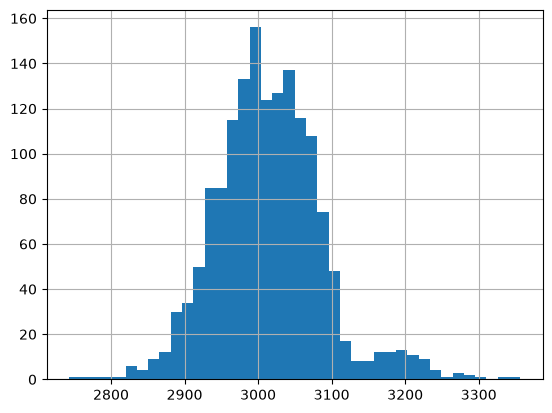

In [26]:
#센서분포 확인
df_clean[0].hist(bins=40)

In [27]:
# 분산 확인 =>  거의 0이면 의미 업는 값 => 삭제대상
df_clean.var().sort_values().head(20)

42     0.0
49     0.0
533    0.0
532    0.0
531    0.0
530    0.0
529    0.0
528    0.0
534    0.0
535    0.0
315    0.0
322    0.0
314    0.0
313    0.0
537    0.0
536    0.0
329    0.0
330    0.0
327    0.0
328    0.0
dtype: float64

In [28]:
# 남아있는 센서중 상관관계파악
corr = df_clean.corr()

In [29]:
# pass,fail 비율 확인
print(y.value_counts())

print("\n비율(%)")
print(y.value_counts(normalize=True) * 100)

0
-1    1463
 1     104
Name: count, dtype: int64

비율(%)
0
-1    93.363114
 1     6.636886
Name: proportion, dtype: float64


fail 93% pass 6%

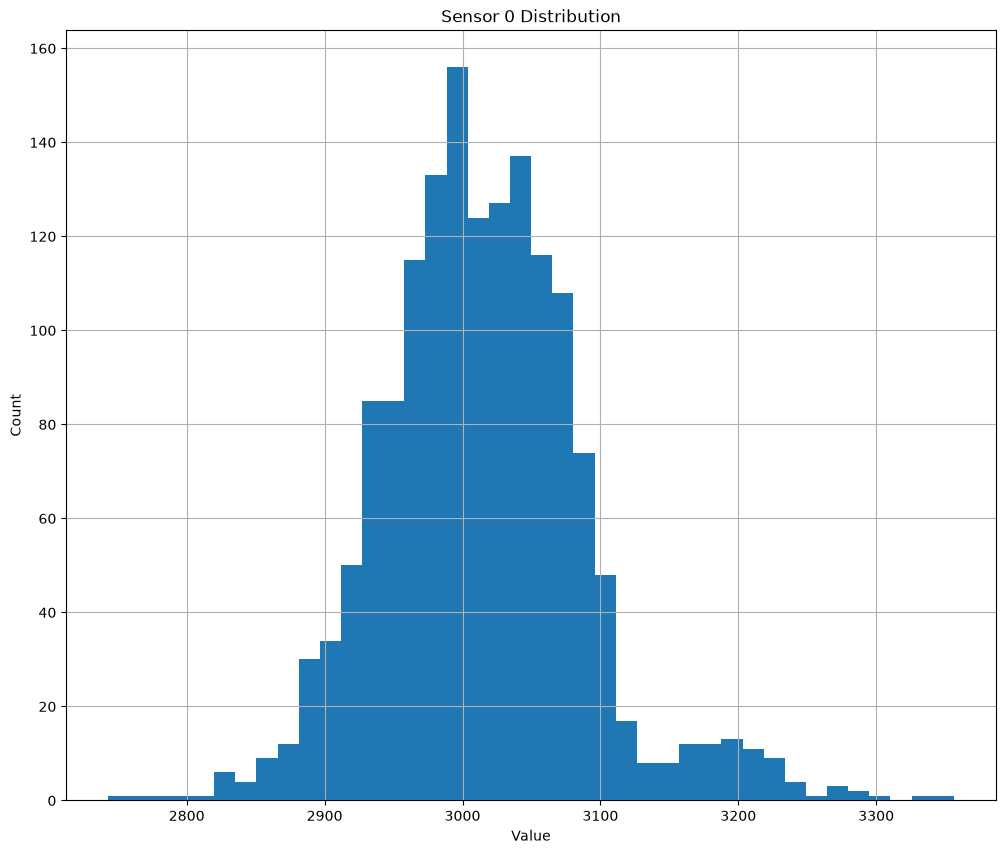

In [30]:
plt.figure(figsize=(12, 10))
df_clean[0].hist(bins=40)

plt.title("Sensor 0 Distribution")
plt.xlabel("Value")
plt.ylabel("Count")

plt.show()

# 일정 구간에서 압도적으로 count값이 높음

In [31]:
# 분산이 거의 0이면 의미 없는 값 
variance = df_clean.var()
variance.sort_values().head(20)

42     0.0
49     0.0
533    0.0
532    0.0
531    0.0
530    0.0
529    0.0
528    0.0
534    0.0
535    0.0
315    0.0
322    0.0
314    0.0
313    0.0
537    0.0
536    0.0
329    0.0
330    0.0
327    0.0
328    0.0
dtype: float64

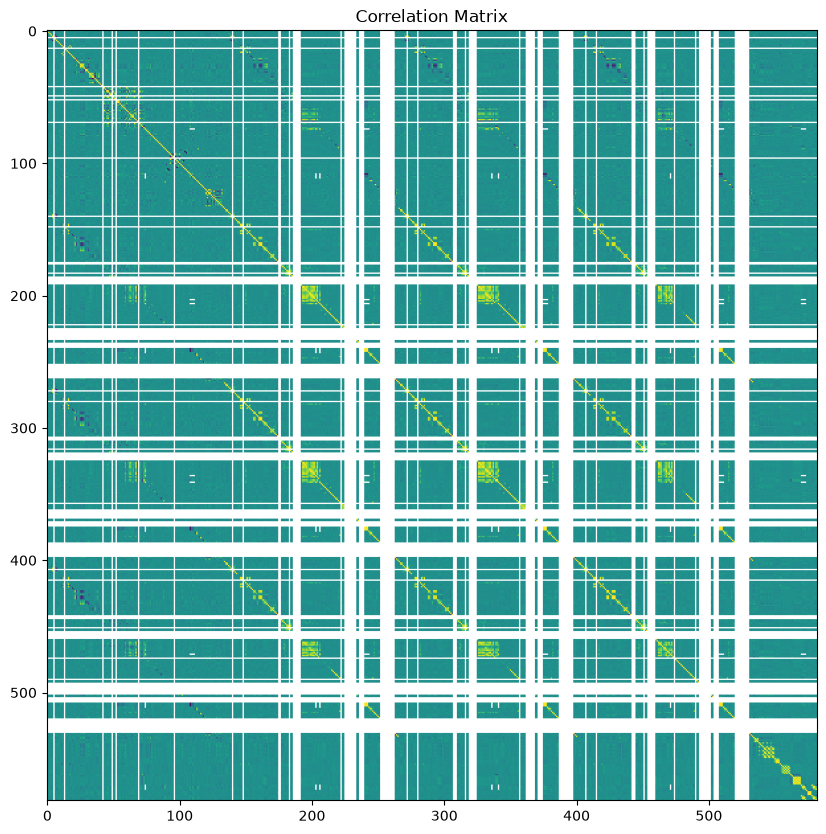

In [32]:
corr = df_clean.iloc[:, :].corr()

plt.figure(figsize=(12, 10))
plt.imshow(corr)
plt.title("Correlation Matrix")
plt.show()

### 분산이 0인 센서 찾기

## 분산이 0인 센서 제거

In [33]:
variance = df_clean.var()

zero_var = variance[variance == 0]

print(f"분산이 0인 센서 개수 : {len(zero_var)}")

zero_var

분산이 0인 센서 개수 : 116


5      0.0
13     0.0
42     0.0
49     0.0
52     0.0
      ... 
534    0.0
535    0.0
536    0.0
537    0.0
538    0.0
Length: 116, dtype: float64

In [34]:
#제거
df_clean = df_clean.drop(columns=zero_var.index)

print(df_clean.shape)

(1567, 466)


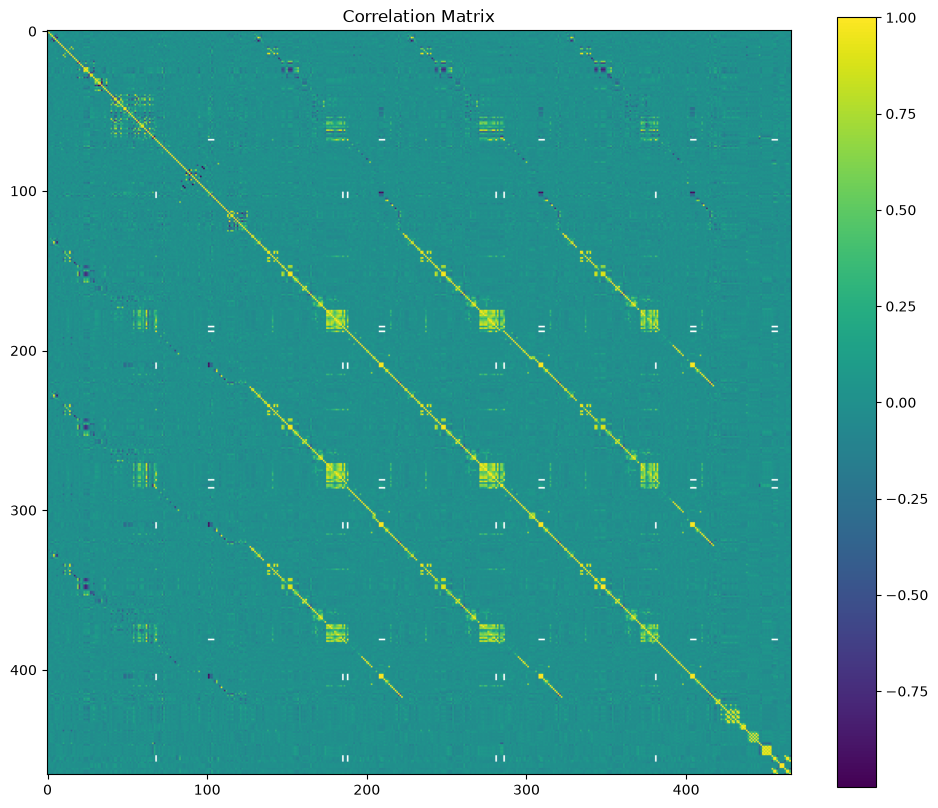

In [35]:
# 다시 상관관계 확인
corr = df_clean.iloc[:, :].corr()

plt.figure(figsize=(12,10))
plt.imshow(corr)

plt.colorbar()
plt.title("Correlation Matrix")

plt.show()